Unstructured Text Analysis & Automated Triage with TF-IDF
Course: Data Science Tools & Techniques

Instructions:
Complete each TODO section below. You can run this file interactively cell-by-cell
in VS Code / PyCharm / Spyder (using the `# %%` markers) or directly via terminal:
    python lab15_starter.py

## Setup & Dataset Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS,
)
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK resources quietly
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# Load 4 real-world unstructured user discussion categories
CATEGORIES = [
    "sci.electronics",
    "rec.autos",
    "comp.sys.mac.hardware",
    "sci.med",
]

print("Loading dataset...")
raw_data = fetch_20newsgroups(
    subset="all",
    categories=CATEGORIES,
    remove=("headers", "footers", "quotes"),
)

df = pd.DataFrame(
    {
        "text": raw_data.data,
        "true_label": [raw_data.target_names[i] for i in raw_data.target],
    }
)

# Keep posts with meaningful length (> 50 characters)
df = df[df["text"].str.strip().str.len() > 50].reset_index(drop=True)
print(f"Loaded {len(df)} unstructured user posts.\n")

Loading dataset...


Loaded 3703 unstructured user posts.



## Step 1: Text Cleaning, Tokenization & Normalization (10 mins)

In [2]:
sample_post = df["text"].iloc[0][:400]
print("--- Raw Sample Post ---")
print(sample_post)
print("-" * 40)

# TODO 1.1: Tokenize `sample_post` using `word_tokenize`, convert to lowercase,
# and keep only alphabetic tokens (`w.isalpha()`).
tokens = [w.lower() for w in word_tokenize(sample_post) if w.isalpha()]

# TODO 1.2: Remove standard English stopwords using `stopwords.words('english')`.
stop_words = set(stopwords.words("english"))
filtered_tokens = [w for w in tokens if w not in stop_words]

# TODO 1.3: Apply PorterStemmer and WordNetLemmatizer (with pos='v') to `filtered_tokens`.
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_tokens = [stemmer.stem(w) for w in filtered_tokens]
lemmatized_tokens = [lemmatizer.lemmatize(w, pos="v") for w in filtered_tokens]

if filtered_tokens is not None:
    print("Filtered Tokens:  ", filtered_tokens[:12])
    print("Stemmed Roots:    ", stemmed_tokens[:12])
    print("Lemmatized Words: ", lemmatized_tokens[:12])

--- Raw Sample Post ---

My Honda has a cable release that can be locked out with the ignition key.
The valet key can be left with someone and will NOT unlock the trunk
or enable the cable release.
----------------------------------------


Filtered Tokens:   ['honda', 'cable', 'release', 'locked', 'ignition', 'key', 'valet', 'key', 'left', 'someone', 'unlock', 'trunk']
Stemmed Roots:     ['honda', 'cabl', 'releas', 'lock', 'ignit', 'key', 'valet', 'key', 'left', 'someon', 'unlock', 'trunk']
Lemmatized Words:  ['honda', 'cable', 'release', 'lock', 'ignition', 'key', 'valet', 'key', 'leave', 'someone', 'unlock', 'trunk']


## Step 2: Bag of Words vs. TF-IDF Feature Extraction (15 mins)


TF-IDF Matrix Shape: (3703, 4000) | Sparsity: 99.04%


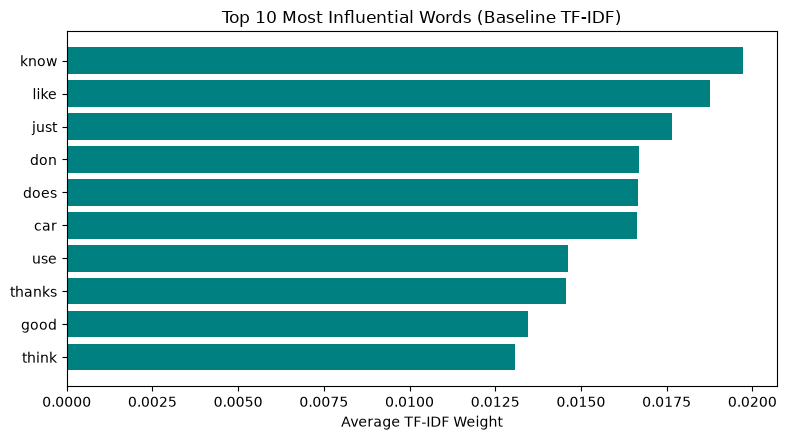

In [3]:
# TODO 2.1: Initialize CountVectorizer and TfidfVectorizer with:
# stop_words='english', max_features=4000, min_df=5
bow_vec = CountVectorizer(stop_words="english", max_features=4000, min_df=5)
tfidf_vec = TfidfVectorizer(stop_words="english", max_features=4000, min_df=5)

# TODO 2.2: Fit and transform `df['text']` to create `X_bow` and `X_tfidf`
X_bow = bow_vec.fit_transform(df["text"])
X_tfidf = tfidf_vec.fit_transform(df["text"])

# TODO 2.3: Calculate matrix sparsity (% of zero entries in `X_tfidf`)
if X_tfidf is not None:
    total_elements = X_tfidf.shape[0] * X_tfidf.shape[1]
    sparsity = 100.0 * (1.0 - (X_tfidf.nnz / total_elements))
    print(f"\nTF-IDF Matrix Shape: {X_tfidf.shape} | Sparsity: {sparsity:.2f}%")

    # TODO 2.4: Compute mean score per feature across documents and plot Top 10 TF-IDF words
    tfidf_means = np.asarray(X_tfidf.mean(axis=0)).ravel()
    top_idx = tfidf_means.argsort()[-10:]
    top_words = tfidf_vec.get_feature_names_out()[top_idx]
    top_scores = tfidf_means[top_idx]

    plt.figure(figsize=(8, 4.5))
    plt.barh(top_words, top_scores, color="teal")
    plt.xlabel("Average TF-IDF Weight")
    plt.title("Top 10 Most Influential Words (Baseline TF-IDF)")
    plt.tight_layout()
    plt.savefig("top_features.png", dpi=150)
    plt.show()

## Step 3: Automated Topic Discovery & Spatial Mapping (15 mins)


Top 8 words per cluster:
Cluster 0: know, like, don, just, does, use, thanks, good
Cluster 1: dsl, cadre, n3jxp, chastity, shameful, surrender, intellect, skepticism
Cluster 2: car, cars, engine, new, just, ford, dealer, like
Cluster 3: mac, apple, drive, monitor, card, thanks, does, know


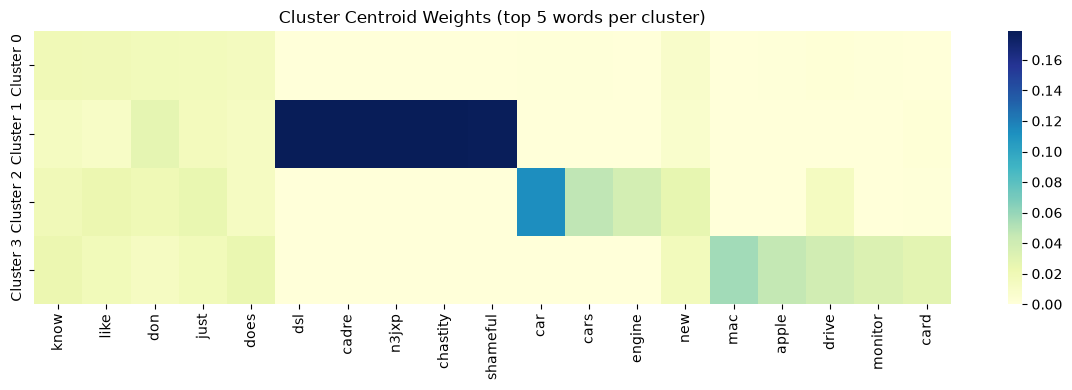

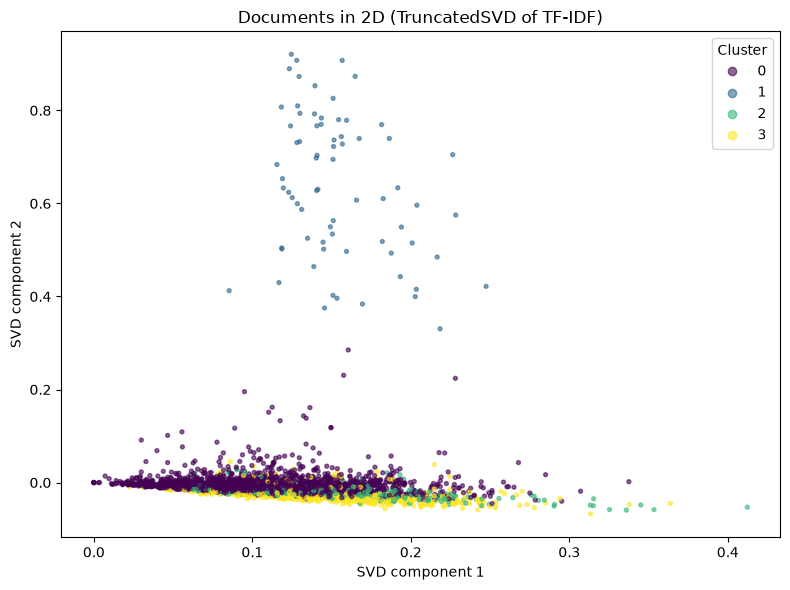

In [4]:
if X_tfidf is not None:
    # TODO 3.1: Fit KMeans with `n_clusters=4, random_state=42, n_init=10` on `X_tfidf`
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
    df["cluster"] = kmeans.fit_predict(X_tfidf)

    # TODO 3.2: Print the top 8 defining TF-IDF words per cluster centroid
    # and plot a seaborn heatmap (`cluster_heatmap.png`) of the top 5 words per cluster.
    terms = tfidf_vec.get_feature_names_out()
    print("\nTop 8 words per cluster:")
    for c in range(4):
        top8 = kmeans.cluster_centers_[c].argsort()[::-1][:8]
        print(f"Cluster {c}: {', '.join(terms[top8])}")

    heat_idx = []
    for c in range(4):
        for i in kmeans.cluster_centers_[c].argsort()[::-1][:5]:
            if i not in heat_idx:
                heat_idx.append(i)
    heat_df = pd.DataFrame(
        kmeans.cluster_centers_[:, heat_idx],
        index=[f"Cluster {c}" for c in range(4)],
        columns=terms[heat_idx],
    )
    plt.figure(figsize=(12, 4))
    sns.heatmap(heat_df, cmap="YlGnBu")
    plt.title("Cluster Centroid Weights (top 5 words per cluster)")
    plt.tight_layout()
    plt.savefig("cluster_heatmap.png", dpi=150)
    plt.show()

    # TODO 3.3: Project `X_tfidf` to 2 dimensions using `TruncatedSVD(n_components=2, random_state=42)`
    # and save a 2D scatter plot (`spatial_mapping.png`) colored by `df["cluster"]`.
    svd = TruncatedSVD(n_components=2, random_state=42)
    coords = svd.fit_transform(X_tfidf)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="viridis", s=8, alpha=0.6)
    plt.legend(*scatter.legend_elements(), title="Cluster")
    plt.xlabel("SVD component 1")
    plt.ylabel("SVD component 2")
    plt.title("Documents in 2D (TruncatedSVD of TF-IDF)")
    plt.tight_layout()
    plt.savefig("spatial_mapping.png", dpi=150)
    plt.show()

## Step 4: Problem-Solving Diagnostics (20 mins)

In [5]:
# Challenge 1 (Noise Filtering):
# TODO 4.1: Build a cleaner `TfidfVectorizer` using `token_pattern=r'\b[a-zA-Z]{3,}\b'`,
# `max_df=0.5`, and custom conversational stopwords (e.g., 'know', 'like', 'just', 'think', 'does', 'use', 'thanks').
# Re-fit KMeans and compare cluster keywords!
filler_words = ["know", "like", "just", "think", "does", "use", "thanks"]
clean_stop_words = list(ENGLISH_STOP_WORDS) + filler_words

tfidf_clean = TfidfVectorizer(
    stop_words=clean_stop_words,
    token_pattern=r"\b[a-zA-Z]{3,}\b",
    max_df=0.5,
    max_features=4000,
    min_df=5,
)
X_clean = tfidf_clean.fit_transform(df["text"])
kmeans_clean = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster_clean"] = kmeans_clean.fit_predict(X_clean)

clean_terms = tfidf_clean.get_feature_names_out()
print("\nTop 8 words per cluster (cleaned vectorizer):")
for c in range(4):
    top8 = kmeans_clean.cluster_centers_[c].argsort()[::-1][:8]
    print(f"Cluster {c}: {', '.join(clean_terms[top8])}")


# Challenge 2 (Hardware Overlap Diagnosis):
# TODO 4.2: Run `pd.crosstab(df['true_label'], df['cluster'])` and inspect overlapping categories.
print("\nTrue label vs cluster (baseline):")
print(pd.crosstab(df["true_label"], df["cluster"]))

# electronics posts that landed in the cluster where most mac hardware posts went
mac_cluster = df.loc[df["true_label"] == "comp.sys.mac.hardware", "cluster"].mode()[0]
mixed = df[(df["true_label"] == "sci.electronics") & (df["cluster"] == mac_cluster)]
print(f"\nElectronics posts sitting in the Mac cluster ({mac_cluster}): {len(mixed)}")
mixed_means = np.asarray(X_tfidf[mixed.index].mean(axis=0)).ravel()
shared_words = terms[mixed_means.argsort()[::-1][:10]]
print("Words pulling them together:", ", ".join(shared_words))

# bigrams
tfidf_bi = TfidfVectorizer(
    stop_words="english", ngram_range=(1, 2), max_features=4000, min_df=5
)
X_bi = tfidf_bi.fit_transform(df["text"])
df["cluster_bi"] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_bi)
print("\nTrue label vs cluster (unigrams + bigrams):")
print(pd.crosstab(df["true_label"], df["cluster_bi"]))


# Challenge 3 (Rant Length Bias):
# TODO 4.3: Compare L2 vector norms (`np.linalg.norm`) of the longest and shortest posts in `X_bow` vs `X_tfidf`.
word_counts = np.asarray(X_bow.sum(axis=1)).ravel()
longest = int(word_counts.argmax())
shortest = int(np.where(word_counts > 0, word_counts, np.inf).argmin())

for name, idx in [("Longest", longest), ("Shortest", shortest)]:
    bow_norm = np.linalg.norm(X_bow[idx].toarray())
    tfidf_norm = np.linalg.norm(X_tfidf[idx].toarray())
    print(
        f"{name} post (doc {idx}, {int(word_counts[idx])} kept words): "
        f"BoW norm = {bow_norm:.2f} | TF-IDF norm = {tfidf_norm:.2f}"
    )


# Challenge 4 (Stakeholder Explainability Audit):
def explain_document(doc_id, matrix, vectorizer, top_n=5):
    """
    TODO 4.4: Return or print the top_n highest-weighted TF-IDF terms and their exact weights
    for a single document `doc_id` (test with doc_id=412).
    """
    row = matrix[doc_id].tocoo()
    names = vectorizer.get_feature_names_out()
    pairs = sorted(zip(row.col, row.data), key=lambda p: p[1], reverse=True)[:top_n]
    result = [(names[i], float(w)) for i, w in pairs]

    print(f"\nTop {top_n} TF-IDF terms for document {doc_id}:")
    for term, weight in result:
        print(f"  {term:<15} {weight:.4f}")
    return result


explain_document(412, X_tfidf, tfidf_vec, top_n=5)
print("Document 412 true label:", df.loc[412, "true_label"], "| cluster:", df.loc[412, "cluster"])


Top 8 words per cluster (cleaned vectorizer):
Cluster 0: cadre, dsl, chastity, surrender, intellect, shameful, skepticism, geb
Cluster 1: don, good, people, time, used, edu, information, want
Cluster 2: car, cars, engine, new, ford, oil, dealer, good
Cluster 3: mac, apple, drive, monitor, card, scsi, video, simms

True label vs cluster (baseline):
cluster                  0   1    2    3
true_label                              
comp.sys.mac.hardware  269   0    2  639
rec.autos              396   0  507    2
sci.electronics        860   0   20   60
sci.med                875  71    0    2

Electronics posts sitting in the Mac cluster (3): 60
Words pulling them together: card, drive, monitor, software, does, mhz, ram, board, help, pin



True label vs cluster (unigrams + bigrams):
cluster_bi               0   1    2    3
true_label                              
comp.sys.mac.hardware  308   0  600    2
rec.autos              396   0    2  507
sci.electronics        887   0   35   18
sci.med                876  71    1    0
Longest post (doc 310, 4483 kept words): BoW norm = 276.24 | TF-IDF norm = 1.00
Shortest post (doc 210, 1 kept words): BoW norm = 1.00 | TF-IDF norm = 1.00

Top 5 TF-IDF terms for document 412:
  discussion      0.4524
  feel            0.3989
  days            0.3855
  need            0.2885
  meant           0.2667
Document 412 true label: rec.autos | cluster: 0
